# LMSYS Results: Colab vs Laptop

This notebook analyzes the LMSYS text training and inference CSVs in `colab_lmsys` and `laptop_lmsys`. It compares recorded training duration and energy, then inference throughput and gross energy per item at each measured batch size.

**Interpretation.** Training files contain four intervals for one seed per model and environment; intervals are not independent repetitions. The CSVs do not include training accuracy or validation metrics, so this notebook does not compare model quality. Laptop inference has five trials per model and batch size. Colab contains ten records for each such configuration, but the repeated trial numbers and distinct idle-power profiles indicate two measurement cohorts. These are kept separate using `idle_w` as a measured profile marker; they are not asserted to be specific GPU or machine identities. Inference means and sample standard deviations are descriptive only. Gross joules per item are used to avoid interpreting idle-subtracted measurements as physical energy. Results apply only to these recorded runs, hardware conditions, and batch sizes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")
ENV_DIRS = {"Colab": Path("colab_lmsys"), "Laptop": Path("laptop_lmsys")}
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (root for root in candidates if all((root / folder).is_dir() for folder in ENV_DIRS.values())),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate colab_lmsys and laptop_lmsys. Run from the project directory "
        "or update PROJECT_ROOT to the directory containing both folders."
    )
print(f"Project root: {PROJECT_ROOT.resolve()}")

Project root: C:\Users\vaikr\Documents\Python\afml_paper


In [2]:
train_frames, infer_frames = [], []
train_files = {"Colab": "text_train_energy.csv", "Laptop": "text_train_energy.csv"}
infer_files = {"Colab": "colab_text_infer_energy.csv", "Laptop": "text_infer_energy.csv"}
for environment, folder in ENV_DIRS.items():
    train_path = PROJECT_ROOT / folder / train_files[environment]
    infer_path = PROJECT_ROOT / folder / infer_files[environment]
    if not train_path.is_file() or not infer_path.is_file():
        raise FileNotFoundError(f"Expected LMSYS training and inference CSVs in {PROJECT_ROOT / folder}")
    train = pd.read_csv(train_path)
    infer = pd.read_csv(infer_path)
    train["environment"] = environment
    infer["environment"] = environment
    train_frames.append(train)
    infer_frames.append(infer)

training = pd.concat(train_frames, ignore_index=True)
inference = pd.concat(infer_frames, ignore_index=True)
required_train = {"environment", "model", "seed", "step_start", "step_end", "tokens_seen", "duration_s", "energy_j_gross", "cumulative_energy_j_gross"}
required_infer = {"environment", "model", "trial", "batch_size", "seq_len", "idle_w", "duration_s", "items_per_s", "j_per_item_gross"}
if missing := required_train - set(training.columns):
    raise ValueError(f"Training CSVs missing columns: {sorted(missing)}")
if missing := required_infer - set(inference.columns):
    raise ValueError(f"Inference CSVs missing columns: {sorted(missing)}")

for column in ["step_start", "step_end", "tokens_seen", "duration_s", "energy_j_gross", "cumulative_energy_j_gross"]:
    training[column] = pd.to_numeric(training[column], errors="coerce")
for column in ["trial", "batch_size", "seq_len", "idle_w", "duration_s", "items_per_s", "j_per_item_gross"]:
    inference[column] = pd.to_numeric(inference[column], errors="coerce")

print("Training coverage (records are intervals, not repeated training runs):")
display(training.groupby(["environment", "model"], as_index=False).agg(
    interval_records=("step_end", "size"), seeds=("seed", "nunique"),
    steps_recorded=("step_end", "max"), tokens_recorded=("tokens_seen", "max"),
))
print("Inference coverage by environment, model, batch size, and idle-power profile:")
display(inference.groupby(["environment", "model", "batch_size", "idle_w"], as_index=False).agg(
    rows=("trial", "size"), distinct_trial_ids=("trial", "nunique"),
))

Training coverage (records are intervals, not repeated training runs):


,environment,model,interval_records,seeds,steps_recorded,tokens_recorded
0,Colab,cfc,4,1,244,1998848
1,Colab,lstm,4,1,244,1998848
2,Colab,transformer,4,1,244,1998848
3,Laptop,cfc,4,1,244,1998848
4,Laptop,lstm,4,1,244,1998848
5,Laptop,transformer,4,1,244,1998848


Inference coverage by environment, model, batch size, and idle-power profile:


,environment,model,batch_size,idle_w,rows,distinct_trial_ids
0,Colab,cfc,1,29.005432,5,5
1,Colab,cfc,1,29.147374,5,5
2,Colab,cfc,16,29.005432,5,5
3,Colab,cfc,16,29.147374,5,5
4,Colab,cfc,64,29.005432,5,5
5,Colab,cfc,64,29.147374,5,5
6,Colab,cfc,137,29.005432,5,5
7,Colab,cfc,137,29.147374,5,5
8,Colab,lstm,1,25.797751,5,5
9,Colab,lstm,1,29.134235,5,5


In [3]:
# Summarize the observed training interval sequence; do not treat intervals as independent runs.
training_summary = (
    training.sort_values("step_end")
    .groupby(["environment", "model"], as_index=False)
    .agg(
        seed=("seed", "first"),
        intervals=("step_end", "size"),
        final_step=("step_end", "max"),
        total_tokens=("tokens_seen", "max"),
        training_time_s=("duration_s", "sum"),
        gross_training_energy_j=("cumulative_energy_j_gross", "max"),
        gross_j_per_token=("energy_j_gross", "sum"),
        peak_memory_mb=("peak_mem_mb", "max"),
    )
)
training_summary["gross_j_per_token"] /= training_summary["total_tokens"]

# `idle_w` distinguishes the two recorded Colab cohorts. Rank them within model because no
# run/session identifier exists in the source files; the labels are not hardware identities.
inference = inference.copy()
inference["profile"] = "single measured cohort"
colab_mask = inference["environment"] == "Colab"
for model, index in inference.loc[colab_mask].groupby("model").groups.items():
    profile_levels = sorted(inference.loc[index, "idle_w"].dropna().unique())
    profile_names = {idle: f"Colab profile {i + 1}" for i, idle in enumerate(profile_levels)}
    inference.loc[index, "profile"] = inference.loc[index, "idle_w"].map(profile_names)

inference_summary = (
    inference.groupby(["environment", "profile", "model", "batch_size", "seq_len"], as_index=False)
    .agg(
        trials=("trial", "nunique"),
        throughput_mean_items_s=("items_per_s", "mean"),
        throughput_sd_items_s=("items_per_s", "std"),
        gross_j_per_item_mean=("j_per_item_gross", "mean"),
        gross_j_per_item_sd=("j_per_item_gross", "std"),
        duration_mean_s=("duration_s", "mean"),
    )
    .sort_values(["model", "batch_size", "environment", "profile"])
    .reset_index(drop=True)
)
print("Training summary:")
display(training_summary.round(5))
print("Inference summary (means and sample SD across trial IDs):")
display(inference_summary.round(5))
print("\nCheck: inference sample counts per configuration:")
display(inference_summary[["environment", "profile", "model", "batch_size", "trials"]])

Training summary:


,environment,model,seed,intervals,final_step,total_tokens,training_time_s,gross_training_energy_j,gross_j_per_token,peak_memory_mb
0,Colab,cfc,1337,4,244,1998848,568.30421,23874.77175,0.01194,1576.11426
1,Colab,lstm,1337,4,244,1998848,35.77567,2412.67898,0.00121,1507.90479
2,Colab,transformer,1337,4,244,1998848,42.84455,2878.56575,0.00144,2138.09766
3,Laptop,cfc,1337,4,244,1998848,680.53463,17486.73488,0.00875,1576.11426
4,Laptop,lstm,1337,4,244,1998848,36.11240,1943.74196,0.00097,1508.52979
5,Laptop,transformer,1337,4,244,1998848,44.13426,2119.43065,0.00106,2138.09180


Inference summary (means and sample SD across trial IDs):


,environment,profile,model,batch_size,seq_len,trials,throughput_mean_items_s,throughput_sd_items_s,gross_j_per_item_mean,gross_j_per_item_sd,duration_mean_s
0,Colab,Colab profile 1,cfc,1,256,5,448.05370,13.59813,0.06095,0.00204,20.33743
1,Colab,Colab profile 2,cfc,1,256,5,429.60598,13.40280,0.06553,0.00259,20.26165
2,Laptop,single measured cohort,cfc,1,256,5,110.11982,1.53135,0.07364,0.00072,20.92585
3,Colab,Colab profile 1,cfc,16,256,5,7064.35071,197.74512,0.00396,0.00011,20.29338
4,Colab,Colab profile 2,cfc,16,256,5,6972.70854,287.22056,0.00405,0.00015,20.20415
5,Laptop,single measured cohort,cfc,16,256,5,1804.18262,8.54120,0.00467,0.00004,20.43289
6,Colab,Colab profile 1,cfc,64,256,5,26794.95045,935.34050,0.00112,0.00003,20.29841
7,Colab,Colab profile 2,cfc,64,256,5,25868.34975,797.72480,0.00117,0.00003,20.26804
8,Laptop,single measured cohort,cfc,64,256,5,6912.84849,95.92556,0.00163,0.00049,21.33404
9,Colab,Colab profile 1,cfc,137,256,5,53758.69312,850.01845,0.00073,0.00002,20.35230



Check: inference sample counts per configuration:


,environment,profile,model,batch_size,trials
0,Colab,Colab profile 1,cfc,1,5
1,Colab,Colab profile 2,cfc,1,5
2,Laptop,single measured cohort,cfc,1,5
3,Colab,Colab profile 1,cfc,16,5
4,Colab,Colab profile 2,cfc,16,5
5,Laptop,single measured cohort,cfc,16,5
6,Colab,Colab profile 1,cfc,64,5
7,Colab,Colab profile 2,cfc,64,5
8,Laptop,single measured cohort,cfc,64,5
9,Colab,Colab profile 1,cfc,137,5


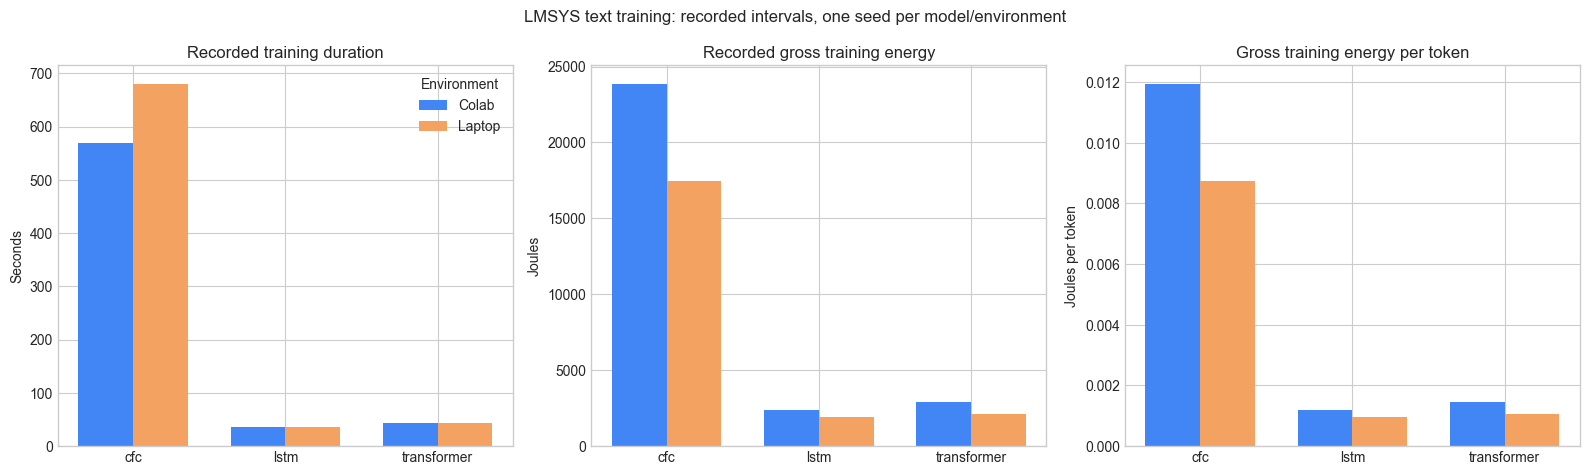

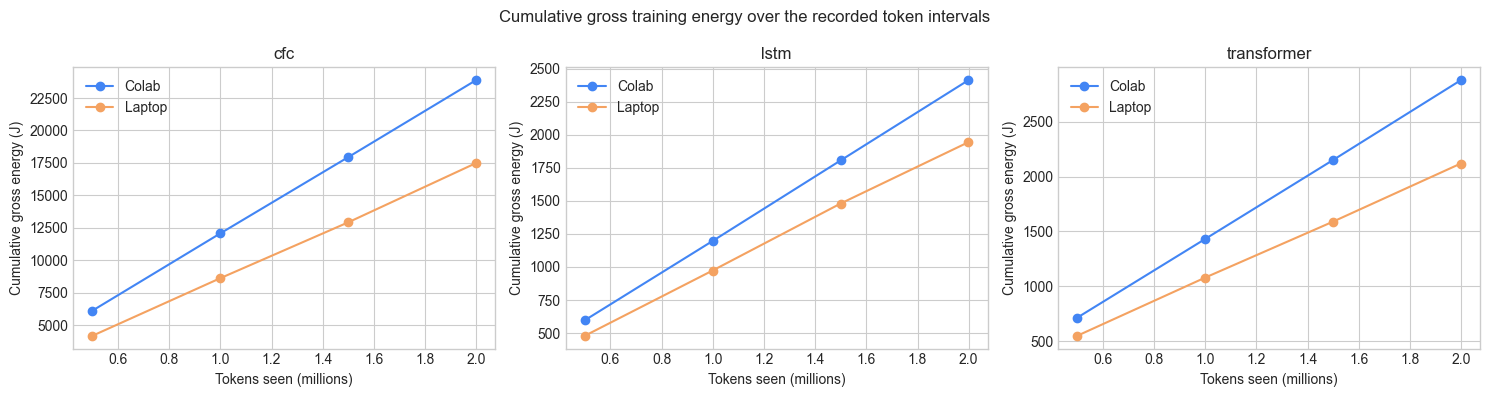

In [4]:
models = sorted(training["model"].dropna().unique())
colors = {"Colab": "#4285F4", "Laptop": "#F4A261"}
x = np.arange(len(models))
width = 0.36
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for axis, metric, title, ylabel in [
    (axes[0], "training_time_s", "Recorded training duration", "Seconds"),
    (axes[1], "gross_training_energy_j", "Recorded gross training energy", "Joules"),
    (axes[2], "gross_j_per_token", "Gross training energy per token", "Joules per token"),
]:
    for offset, environment in zip([-width / 2, width / 2], ["Colab", "Laptop"]):
        values = (training_summary[training_summary["environment"] == environment]
                  .set_index("model")[metric].reindex(models))
        axis.bar(x + offset, values, width, label=environment, color=colors[environment])
    axis.set(title=title, ylabel=ylabel, xticks=x, xticklabels=models)
axes[0].legend(title="Environment")
fig.suptitle("LMSYS text training: recorded intervals, one seed per model/environment")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), sharey=False)
if len(models) == 1:
    axes = [axes]
for axis, model in zip(axes, models):
    for environment in ["Colab", "Laptop"]:
        curve = training[(training["model"] == model) & (training["environment"] == environment)].sort_values("tokens_seen")
        axis.plot(curve["tokens_seen"] / 1e6, curve["cumulative_energy_j_gross"], marker="o",
                  label=environment, color=colors[environment])
    axis.set(title=model, xlabel="Tokens seen (millions)", ylabel="Cumulative gross energy (J)")
    axis.legend()
fig.suptitle("Cumulative gross training energy over the recorded token intervals")
fig.tight_layout()
plt.show()

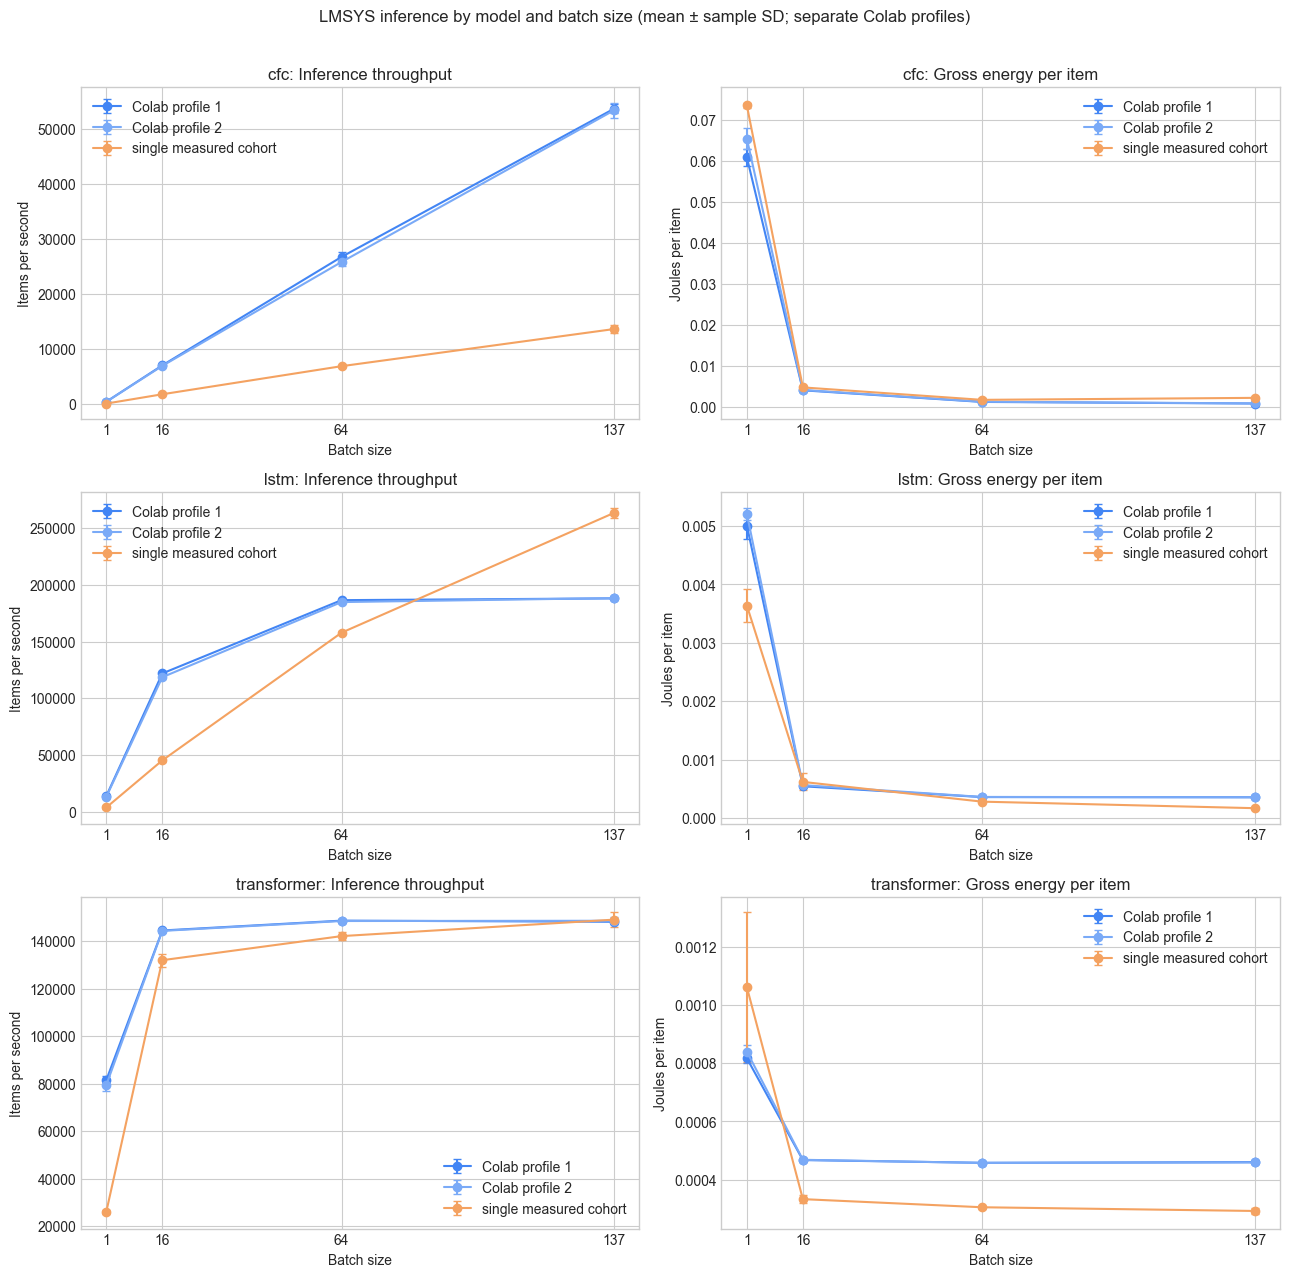

In [5]:
batch_sizes = sorted(inference_summary["batch_size"].dropna().unique())
profile_order = ["Colab profile 1", "Colab profile 2", "single measured cohort"]
profile_colors = {"Colab profile 1": "#4285F4", "Colab profile 2": "#7AAAF7", "single measured cohort": "#F4A261"}
fig, axes = plt.subplots(len(models), 2, figsize=(13, 4.2 * len(models)), squeeze=False)
for row, model in enumerate(models):
    for column, metric, sd_metric, title, ylabel in [
        (0, "throughput_mean_items_s", "throughput_sd_items_s", "Inference throughput", "Items per second"),
        (1, "gross_j_per_item_mean", "gross_j_per_item_sd", "Gross energy per item", "Joules per item"),
    ]:
        axis = axes[row, column]
        for profile in profile_order:
            subset = inference_summary[(inference_summary["model"] == model) &
                                       (inference_summary["profile"] == profile)].set_index("batch_size").reindex(batch_sizes)
            if subset[metric].notna().any():
                axis.errorbar(batch_sizes, subset[metric], yerr=subset[sd_metric], marker="o",
                              capsize=3, label=profile, color=profile_colors[profile])
        axis.set(title=f"{model}: {title}", xlabel="Batch size", ylabel=ylabel, xticks=batch_sizes)
        axis.legend()
fig.suptitle("LMSYS inference by model and batch size (mean ± sample SD; separate Colab profiles)", y=1.01)
fig.tight_layout()
plt.show()

In [6]:
def metric_value(frame, filters, column):
    mask = pd.Series(True, index=frame.index)
    for key, value in filters.items():
        mask &= frame[key] == value
    result = frame.loc[mask, column]
    if result.empty or pd.isna(result.iloc[0]):
        return np.nan
    return float(result.iloc[0])

paragraphs = []
for model in models:
    colab = training_summary[(training_summary["environment"] == "Colab") & (training_summary["model"] == model)].iloc[0]
    laptop = training_summary[(training_summary["environment"] == "Laptop") & (training_summary["model"] == model)].iloc[0]
    faster = "Colab" if colab["training_time_s"] < laptop["training_time_s"] else "Laptop"
    lower_energy = "Colab" if colab["gross_training_energy_j"] < laptop["gross_training_energy_j"] else "Laptop"
    paragraphs.append(
        f"For **{model}** training over {int(colab['total_tokens']):,} recorded tokens "
        f"({int(colab['final_step'])} steps), elapsed interval time was {colab['training_time_s']:.1f} s on Colab "
        f"and {laptop['training_time_s']:.1f} s on the laptop; the shorter recorded time was on {faster}. "
        f"Gross energy was {colab['gross_training_energy_j']:.0f} J on Colab and "
        f"{laptop['gross_training_energy_j']:.0f} J on the laptop; the lower recorded energy was on {lower_energy}."
    )
    for batch in batch_sizes:
        laptop_rate = metric_value(inference_summary, {"environment": "Laptop", "model": model, "batch_size": batch}, "throughput_mean_items_s")
        laptop_energy = metric_value(inference_summary, {"environment": "Laptop", "model": model, "batch_size": batch}, "gross_j_per_item_mean")
        colab_rows = inference_summary[(inference_summary["environment"] == "Colab") &
                                       (inference_summary["model"] == model) &
                                       (inference_summary["batch_size"] == batch)]
        colab_parts = []
        for _, observed in colab_rows.iterrows():
            label = observed["profile"].replace("Colab ", "")
            colab_parts.append(
                f"{label}: {observed['throughput_mean_items_s']:.1f} items/s and "
                f"{observed['gross_j_per_item_mean']:.5f} J/item"
            )
        paragraphs.append(
            f"At batch size {int(batch)}, **{model}** inference on the laptop averaged {laptop_rate:.1f} items/s "
            f"and {laptop_energy:.5f} gross J/item. The separate Colab cohorts measured "
            + "; ".join(colab_parts)
            + "."
        )

conclusion = (
    "## Paper-ready descriptive conclusion\n\n"
    "The recorded LMSYS runs show model- and batch-size-dependent runtime and energy differences between the Colab "
    "and laptop environments. The measurements support descriptive comparisons of the specific runs, not claims about "
    "model quality or general hardware superiority.\n\n"
    + "\n\n".join(paragraphs)
    + "\n\nTraining results summarize interval records from one seed per model and environment; the intervals are not "
    "independent replications. Colab inference means are reported by distinct idle-power profile rather than pooling "
    "the two cohorts, and laptop inference summaries use five trial IDs per configuration. No statistical significance "
    "is inferred. Training accuracy is unavailable in the input files, and no validation or test performance conclusion "
    "can be drawn from these measurements. The Colab profile labels are descriptive markers only, not hardware IDs."
)
display(Markdown(conclusion))

## Paper-ready descriptive conclusion

The recorded LMSYS runs show model- and batch-size-dependent runtime and energy differences between the Colab and laptop environments. The measurements support descriptive comparisons of the specific runs, not claims about model quality or general hardware superiority.

For **cfc** training over 1,998,848 recorded tokens (244 steps), elapsed interval time was 568.3 s on Colab and 680.5 s on the laptop; the shorter recorded time was on Colab. Gross energy was 23875 J on Colab and 17487 J on the laptop; the lower recorded energy was on Laptop.

At batch size 1, **cfc** inference on the laptop averaged 110.1 items/s and 0.07364 gross J/item. The separate Colab cohorts measured profile 1: 448.1 items/s and 0.06095 J/item; profile 2: 429.6 items/s and 0.06553 J/item.

At batch size 16, **cfc** inference on the laptop averaged 1804.2 items/s and 0.00467 gross J/item. The separate Colab cohorts measured profile 1: 7064.4 items/s and 0.00396 J/item; profile 2: 6972.7 items/s and 0.00405 J/item.

At batch size 64, **cfc** inference on the laptop averaged 6912.8 items/s and 0.00163 gross J/item. The separate Colab cohorts measured profile 1: 26795.0 items/s and 0.00112 J/item; profile 2: 25868.3 items/s and 0.00117 J/item.

At batch size 137, **cfc** inference on the laptop averaged 13671.1 items/s and 0.00212 gross J/item. The separate Colab cohorts measured profile 1: 53758.7 items/s and 0.00073 J/item; profile 2: 53471.6 items/s and 0.00076 J/item.

For **lstm** training over 1,998,848 recorded tokens (244 steps), elapsed interval time was 35.8 s on Colab and 36.1 s on the laptop; the shorter recorded time was on Colab. Gross energy was 2413 J on Colab and 1944 J on the laptop; the lower recorded energy was on Laptop.

At batch size 1, **lstm** inference on the laptop averaged 3544.8 items/s and 0.00364 gross J/item. The separate Colab cohorts measured profile 1: 13618.4 items/s and 0.00501 J/item; profile 2: 13006.6 items/s and 0.00521 J/item.

At batch size 16, **lstm** inference on the laptop averaged 45125.3 items/s and 0.00062 gross J/item. The separate Colab cohorts measured profile 1: 121850.8 items/s and 0.00055 J/item; profile 2: 118558.2 items/s and 0.00057 J/item.

At batch size 64, **lstm** inference on the laptop averaged 157821.8 items/s and 0.00028 gross J/item. The separate Colab cohorts measured profile 1: 186555.3 items/s and 0.00036 J/item; profile 2: 184853.6 items/s and 0.00036 J/item.

At batch size 137, **lstm** inference on the laptop averaged 263595.3 items/s and 0.00017 gross J/item. The separate Colab cohorts measured profile 1: 188101.4 items/s and 0.00036 J/item; profile 2: 188382.2 items/s and 0.00036 J/item.

For **transformer** training over 1,998,848 recorded tokens (244 steps), elapsed interval time was 42.8 s on Colab and 44.1 s on the laptop; the shorter recorded time was on Colab. Gross energy was 2879 J on Colab and 2119 J on the laptop; the lower recorded energy was on Laptop.

At batch size 1, **transformer** inference on the laptop averaged 26150.2 items/s and 0.00106 gross J/item. The separate Colab cohorts measured profile 1: 81489.6 items/s and 0.00082 J/item; profile 2: 79465.1 items/s and 0.00084 J/item.

At batch size 16, **transformer** inference on the laptop averaged 131921.5 items/s and 0.00033 gross J/item. The separate Colab cohorts measured profile 1: 144413.1 items/s and 0.00047 J/item; profile 2: 144239.5 items/s and 0.00047 J/item.

At batch size 64, **transformer** inference on the laptop averaged 142046.8 items/s and 0.00031 gross J/item. The separate Colab cohorts measured profile 1: 148559.7 items/s and 0.00046 J/item; profile 2: 148397.1 items/s and 0.00046 J/item.

At batch size 137, **transformer** inference on the laptop averaged 148974.8 items/s and 0.00029 gross J/item. The separate Colab cohorts measured profile 1: 148072.6 items/s and 0.00046 J/item; profile 2: 148501.8 items/s and 0.00046 J/item.

Training results summarize interval records from one seed per model and environment; the intervals are not independent replications. Colab inference means are reported by distinct idle-power profile rather than pooling the two cohorts, and laptop inference summaries use five trial IDs per configuration. No statistical significance is inferred. Training accuracy is unavailable in the input files, and no validation or test performance conclusion can be drawn from these measurements. The Colab profile labels are descriptive markers only, not hardware IDs.